# Lecture 3 — Class Exercise
## Line Charts: CO2 Emissions

> **Push to:** `week03/lecture03_exercise.ipynb` in your GitHub repo

### Remember:
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title


In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Dataset: CO2 Emissions by Country 2000-2022
# Source: Our World in Data (https://ourworldindata.org/co2-emissions)
df = pd.read_csv('../data/co2_emissions.csv')
print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}-{df['Year'].max()}")
print(df.head())


Loaded: 345 rows | Countries: 15 | Years: 2000-2022
         Country         Region  Year  CO2_Mt  CO2_per_capita
0  United States  North America  2000  5857.6            1.32
1  United States  North America  2001  5724.0            1.26
2  United States  North America  2002  5652.8            1.11
3  United States  North America  2003  5592.8            1.29
4  United States  North America  2004  5743.2            1.12


In [2]:
# Explore before building

print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))


Countries: <ArrowStringArray>
[ 'United States',          'China',          'India',        'Germany',
 'United Kingdom',         'France',         'Brazil',          'Japan',
         'Canada',      'Australia',    'South Korea',         'Russia',
   'South Africa',         'Mexico',      'Indonesia']
Length: 15, dtype: str

CO2 range: 125.3 to 12409.5 Mt

Regional averages (2022):
Region
Asia             3531.1
North America    2393.8
Latin America     629.2
Africa            534.4
Europe            496.5
Oceania           493.7
Name: CO2_Mt, dtype: float64


---
## Task — Multi-Series Line Chart with Highlight

**What to build:** A line chart showing CO2 emissions over time for **all Asian countries** in the dataset, with one country highlighted.

**Requirements:**
- All countries shown (for context), but only **one highlighted in colour** — your choice which
- All other lines in grey (#EEEEEE), thinner
- Highlighted country **labelled directly** at the end of its line (not in a legend)
- Insight title that names the highlighted country and its story

Asian countries in the dataset: ['China', 'India', 'Indonesia', 'Japan', 'South Korea']


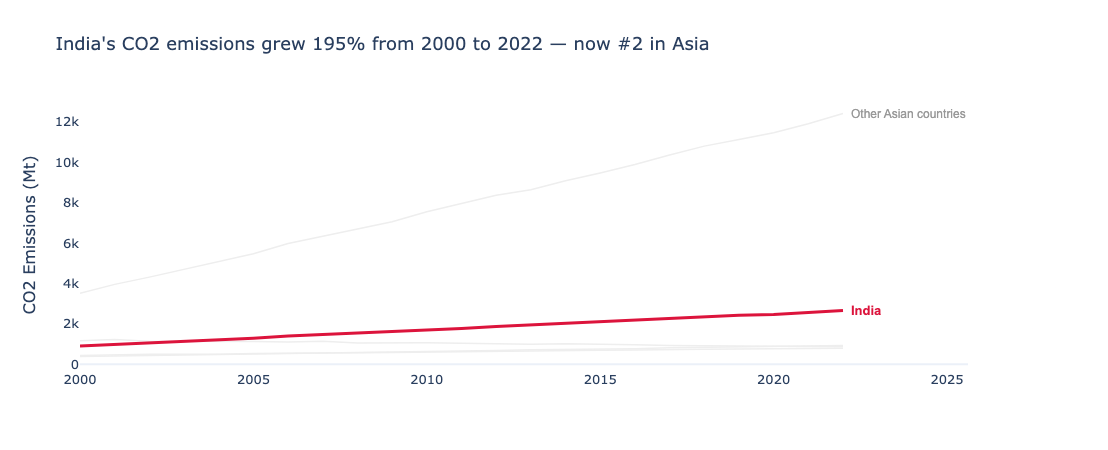

In [3]:
# Task — Multi-series line with highlight
# YOUR CODE HERE
highlight = 'India'
asia = df.loc[df['Region'] == 'Asia'].copy()
print("Asian countries in the dataset:", sorted(asia['Country'].unique()))

others = asia.loc[asia['Country'] != highlight].sort_values('Year')   
star   = asia.loc[asia['Country'] == highlight].sort_values('Year') 
plot_df = pd.concat([others, star]) 
color_map = {c: 'crimson' if c == highlight else '#EEEEEE' for c in asia['Country'].unique()}
first_year = asia['Year'].min()  
last_year  = asia['Year'].max()

start_val = star.loc[star['Year'] == first_year, 'CO2_Mt'].values[0]
end_val   = star.loc[star['Year'] == last_year,  'CO2_Mt'].values[0]
growth_pct = (end_val - start_val) / start_val * 100
last_year_asia = asia.loc[asia['Year'] == last_year].sort_values('CO2_Mt', ascending=False)
rank = list(last_year_asia['Country']).index(highlight) + 1

title = f"{highlight}'s CO2 emissions grew {growth_pct:.0f}% from {first_year} to {last_year} — now #{rank} in Asia"

fig = px.line(
    plot_df, x='Year', y='CO2_Mt',
    color='Country',                       
    color_discrete_map=color_map,          
    labels={'CO2_Mt': 'CO2 Emissions (Mt)', 'Year': ''},   
    title=title,
    template='plotly_white',              
    height=450,
)

fig.update_traces(line=dict(width=1.5), showlegend=False)
fig.update_traces(line=dict(width=3), selector=dict(name=highlight))
star_end = star.loc[star['Year'] == last_year].iloc[0]

fig.add_annotation(
    x=star_end['Year'], y=star_end['CO2_Mt'],   
    text=highlight,
    showarrow=False,                            
    xanchor='left', xshift=6,                   
    font=dict(color='crimson', size=13, family='Arial', weight='bold'),
)

top_other = others.loc[others['Year'] == last_year].sort_values('CO2_Mt', ascending=False).iloc[0]
fig.add_annotation(
    x=top_other['Year'], y=top_other['CO2_Mt'],
    text='Other Asian countries',
    showarrow=False, xanchor='left', xshift=6,
    font=dict(color='#999999', size=12, family='Arial'),
)

fig.update_layout(
    font=dict(size=13),
    xaxis=dict(showgrid=False),                 
    yaxis=dict(showgrid=False),
    margin=dict(r=140),                         
)

fig.show()